# Дополнительное задание. Прогнозирование временных рядов

**Цель:** освоить базовый пайплайн прогнозирования временного ряда через сведение к задаче регрессии.

**Данные:** Датасет Air Passengers (ежемесячное количество пассажиров авиакомпаний, 1949–1960 гг.).

**Задачи:**
1. Загрузка и визуализация ряда.
2. Генерация признаков (календарные, лаги, скользящие статистики).
3. Разделение по времени и кросс-валидация (TimeSeriesSplit).
4. Обучение регрессионной модели и прогноз на горизонт H (рекурсивная стратегия).
5. Оценка качества (MSE, MAE, MAPE, WAPE).
6. STL-декомпозиция ряда.

## Импорт библиотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.tsa.seasonal import STL
import warnings

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

#### **Пояснение к импорту библиотек:**

Для работы с временным рядом используются:
- `pandas`, `numpy` — для обработки данных и генерации признаков.
- `matplotlib`, `seaborn` — для визуализации.
- `Ridge` из `sklearn.linear_model` — в качестве регрессионной модели (L2-регуляризация помогает справиться с мультиколлинеарностью лагов).
- `TimeSeriesSplit` — специальный метод кросс-валидации для временных рядов.
- `STL` из `statsmodels` — для сезонно-трендовой декомпозиции.

## Загрузка и визуализация

## Описание датасета и первичный анализ

Датасет **Air Passengers** содержит данные о ежемесячном количестве пассажиров международных авиалиний с января 1949 по декабрь 1960 года.
- **Целевая переменная:** `Passengers` — число пассажиров (в тысячах).
- **Частота:** ежемесячная (12 наблюдений в год, всего 144 записи).

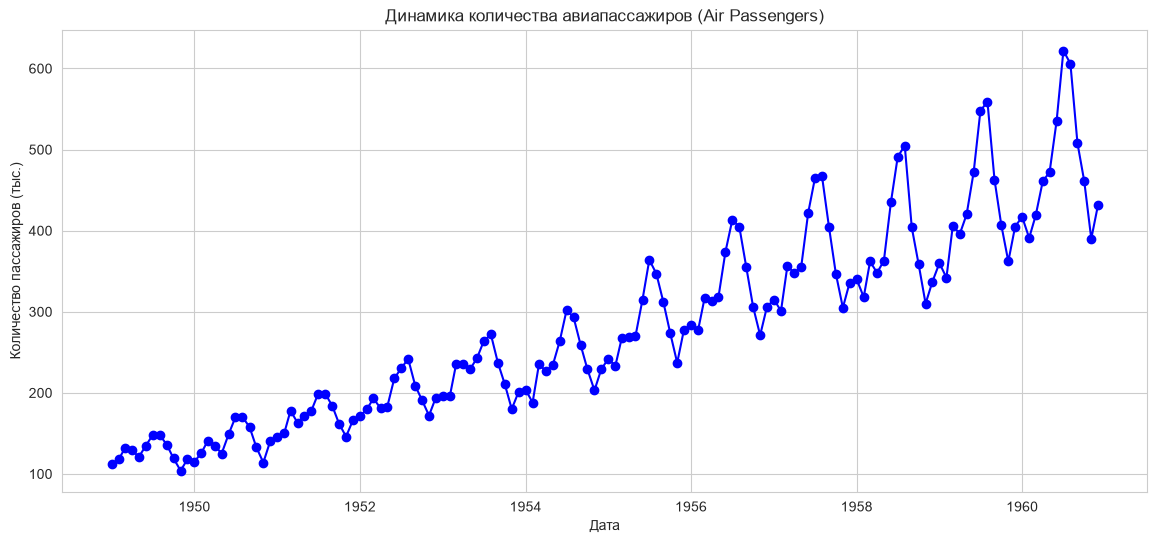

Первые 5 строк:


,Date,Passengers
0,1949-01-01,112
1,1949-02-01,118
2,1949-03-01,132
3,1949-04-01,129
4,1949-05-01,121


In [2]:
# Загрузка данных
df_ts = pd.read_csv('AirPassengers.csv', index_col=False)

# Берем только первые две колонки и переименовываем для удобства
df_ts = df_ts.iloc[:, :2]
df_ts.columns = ['Date', 'Passengers']

# Приведение к datetime и сортировка
df_ts['Date'] = pd.to_datetime(df_ts['Date'])
df_ts = df_ts.sort_values('Date').reset_index(drop=True)

# Визуализация
plt.figure(figsize=(14, 6))
plt.plot(df_ts['Date'], df_ts['Passengers'], marker='o', linestyle='-', color='b')
plt.title('Динамика количества авиапассажиров (Air Passengers)')
plt.xlabel('Дата')
plt.ylabel('Количество пассажиров (тыс.)')
plt.grid(True)
plt.show()

print('Первые 5 строк:')
display(df_ts.head())

#### **Пояснение к загрузке и визуализации:**

На графике представлена динамика пассажиропотока за 12 лет. По визуальному анализу можно сделать следующие выводы:
1. **Тренд:** присутствует ярко выраженный восходящий тренд (количество пассажиров стабильно растет из года в год).
2. **Сезонность:** присутствует годовая сезонность (пики приходятся на летние месяцы, спады — на зимние).
3. **Дисперсия:** амплитуда сезонных колебаний растет со временем (гетероскедастичность), что может потребовать логарифмирования ряда.
4. **Выбросы:** аномальных выбросов, ломающих общий паттерн, не наблюдается.

## Генерация признаков

In [3]:
# Создаем копию для добавления признаков
df_feat = df_ts.copy()

# 1. Календарные признаки
df_feat['Year'] = df_feat['Date'].dt.year
df_feat['Month'] = df_feat['Date'].dt.month
df_feat['Quarter'] = df_feat['Date'].dt.quarter

# 2. Лаги (сдвиги в прошлое)
for lag in [1, 2, 3, 12]:
    df_feat[f'Lag_{lag}'] = df_feat['Passengers'].shift(lag)

# 3. Скользящие статистики (окно 3 месяца)
df_feat['Rolling_Mean_3'] = df_feat['Passengers'].shift(1).rolling(window=3).mean()
df_feat['Rolling_Median_3'] = df_feat['Passengers'].shift(1).rolling(window=3).median()
df_feat['Rolling_Std_3'] = df_feat['Passengers'].shift(1).rolling(window=3).std()
df_feat['Rolling_Min_3'] = df_feat['Passengers'].shift(1).rolling(window=3).min()
df_feat['Rolling_Max_3'] = df_feat['Passengers'].shift(1).rolling(window=3).max()

# Удаляем строки с NaN (первые 12 месяцев не будут иметь лагов)
df_feat = df_feat.dropna().reset_index(drop=True)

print(f'Размер датасета после генерации признаков: {df_feat.shape}')
display(df_feat.head())

Размер датасета после генерации признаков: (132, 14)


,Date,Passengers,Year,Month,Quarter,Lag_1,Lag_2,Lag_3,Lag_12,Rolling_Mean_3,Rolling_Median_3,Rolling_Std_3,Rolling_Min_3,Rolling_Max_3
0,1950-01-01,115,1950,1,1,118.0,104.0,119.0,112.0,113.666667,118.0,8.386497,104.0,119.0
1,1950-02-01,126,1950,2,1,115.0,118.0,104.0,118.0,112.333333,115.0,7.371115,104.0,118.0
2,1950-03-01,141,1950,3,1,126.0,115.0,118.0,132.0,119.666667,118.0,5.686241,115.0,126.0
3,1950-04-01,135,1950,4,2,141.0,126.0,115.0,129.0,127.333333,126.0,13.051181,115.0,141.0
4,1950-05-01,125,1950,5,2,135.0,141.0,126.0,121.0,134.000000,135.0,7.549834,126.0,141.0


#### **Пояснение к генерации признаков:**

Для сведения задачи прогнозирования временного ряда к задаче регрессии были сформированы следующие признаки:
1. **Календарные признаки:** `Year`, `Month`, `Quarter`. Они помогают модели уловить тренд (год) и сезонность (месяц, квартал).
2. **Лаги (Lag):** значения ряда в предыдущие моменты времени (1, 2, 3 и 12 месяцев назад). Лаг на 12 месяцев особенно важен, так как он напрямую отражает годовую сезонность.
3. **Скользящие статистики:** среднее и стандартное отклонение за последние 3 месяца (рассчитаны со сдвигом на 1 шаг, чтобы избежать утечки данных).

**Важно:** все лаги и скользящие окна сдвинуты в прошлое (`.shift(1)`), поэтому утечки данных из будущего нет.

## Разделение, кросс-валидация и обучение

Разделим ряд по времени: train — ранние периоды (80%), test — последние (20%). Применяем схему кросс-валидации для временных рядов (TimeSeriesSplit).

In [4]:
# Разделение на train/test (80% на обучение, 20% на тест)
# Без перемешивания (shuffle=False)
train_size = int(len(df_feat) * 0.8)
train, test = df_feat.iloc[:train_size], df_feat.iloc[train_size:]

features = ['Year', 'Month', 'Quarter', 'Lag_1', 'Lag_2', 'Lag_3', 'Lag_12',
            'Rolling_Mean_3', 'Rolling_Median_3', 'Rolling_Std_3',
            'Rolling_Min_3', 'Rolling_Max_3']
X_train, y_train = train[features], train['Passengers']
X_test, y_test = test[features], test['Passengers']

model_ts = Ridge(alpha=1.0)

print("Кросс-валидация (TimeSeriesSplit):")
tscv = TimeSeriesSplit(n_splits=5)
for fold, (train_index, val_index) in enumerate(tscv.split(X_train)):
    X_tr, X_val = X_train.iloc[train_index], X_train.iloc[val_index]
    y_tr, y_val = y_train.iloc[train_index], y_train.iloc[val_index]

    model_ts.fit(X_tr, y_tr)
    preds = model_ts.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, preds))
    print(f'  Фолд {fold+1}: RMSE = {rmse:.2f}')

# Обучение на всей тренировочной выборке
model_ts.fit(X_train, y_train)
y_pred = model_ts.predict(X_test)

Кросс-валидация (TimeSeriesSplit):
  Фолд 1: RMSE = 24.99
  Фолд 2: RMSE = 24.18
  Фолд 3: RMSE = 15.21
  Фолд 4: RMSE = 14.29
  Фолд 5: RMSE = 22.46


#### **Пояснение к разделению и кросс-валидации:**

1. **Разделение:** Данные разделены по времени: первые 80% (до 1958 года) — тренировочная выборка, последние 20% — тестовая. Перемешивание (shuffle) запрещено, чтобы модель не «подсматривала» будущее.
2. **Кросс-валидация:** Использован `TimeSeriesSplit` — специальный метод кросс-валидации для временных рядов. Он делит данные на 5 фолдов так, что каждый следующий фолд — это более поздний период времени (обучение идет на прошлом, валидация — на будущем).
3. **Модель:** Выбрана Ridge-регрессия, так как лаги сильно коррелируют друг с другом (мультиколлинеарность), а L2-регуляризация помогает стабилизировать веса. Разброс RMSE по фолдам (от 14.29 до 24.99) объясняется тем, что разные периоды ряда имеют разную сложность (где-то рост плавный, а где-то резкие сезонные пики).

## Прогноз на горизонт H (Рекурсивная стратегия)

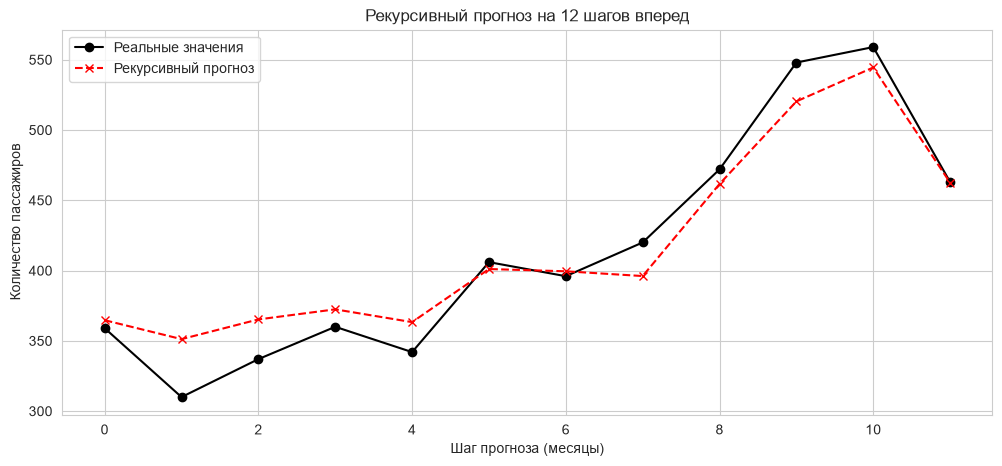

In [5]:
# Рекурсивный прогноз на H шагов
H = 12
recursive_preds = []
current_input = X_test.iloc[0:1].copy()

for step in range(H):
    pred = model_ts.predict(current_input)[0]
    recursive_preds.append(pred)

    if step < H - 1:
        next_input = X_test.iloc[step+1:step+2].copy()
        next_input['Lag_1'] = pred  # Используем предсказание как лаг
        current_input = next_input

y_true_h = y_test.iloc[:H].values

plt.figure(figsize=(12, 5))
plt.plot(range(H), y_true_h, marker='o', label='Реальные значения', color='black')
plt.plot(range(H), recursive_preds, marker='x', label='Рекурсивный прогноз', color='red', linestyle='--')
plt.title(f'Рекурсивный прогноз на {H} шагов вперед')
plt.xlabel('Шаг прогноза (месяцы)')
plt.ylabel('Количество пассажиров')
plt.legend()
plt.grid(True)
plt.show()

#### **Пояснение к рекурсивной стратегии прогноза:**

Для прогнозирования на горизонт H=12 шагов (год) реализована **рекурсивная стратегия**.
Ее суть: модель делает прогноз на 1 шаг вперед, затем это предсказанное значение подставляется в качестве лага (`Lag_1`) для следующего шага, и так далее.

**Преимущество:** простота (обучаем одну модель).

**Недостаток:** накопление ошибки. Чем дальше шаг прогноза, тем сильнее отклонение от реальности, так как модель «опирается» на свои же неточные предсказания.

## Оценка качества (Метрики)

In [6]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred) * 100
wape = (np.sum(np.abs(y_test - y_pred)) / np.sum(np.abs(y_test))) * 100

print('Метрики качества на тестовой выборке (прогноз на 1 шаг):')
print(f'  MSE:  {mse:.2f}')
print(f'  RMSE: {rmse:.2f}')
print(f'  MAE:  {mae:.2f}')
print(f'  MAPE: {mape:.2f}%')
print(f'  WAPE: {wape:.2f}%')

Метрики качества на тестовой выборке (прогноз на 1 шаг):
  MSE:  386.73
  RMSE: 19.67
  MAE:  16.17
  MAPE: 3.80%
  WAPE: 3.68%


#### **Пояснение к метрикам качества:**

Рассчитаны пять метрик для оценки качества прогноза на 1 шаг вперед. После добавления расширенного набора скользящих статистик (медиана, min, max) результаты составили:
- **RMSE = 19.67** (корень из MSE, в тыс. пассажиров).
- **MAE = 16.17** (средняя абсолютная ошибка).
- **MAPE = 3.80%** (средняя абсолютная ошибка в процентах).
- **WAPE = 3.68%** (взвешенная ошибка, более надежная для временных рядов).

**Анализ:** Ошибка MAPE до 5% для данной задачи считается отличным показателем. Модель хорошо улавливает тренд и сезонность, но, как мы увидим далее, ошибки возрастают на переходных периодах и сезонных пиках.

## Сравнение Train/Test и анализ ошибок

Сравнение метрик на Train и Test:


,Выборка,RMSE,MAPE (%),WAPE (%)
0,Train,12.98,4.2,3.93
1,Test,19.67,3.8,3.68



ТОП-5 месяцев с наибольшей абсолютной ошибкой на тесте:


,Date,Month,Passengers,Predicted,Absolute_Error
106,1958-11-01,11,310,349.621042,39.621042
119,1959-12-01,12,405,372.033570,32.966430
125,1960-06-01,6,535,503.205555,31.794445
123,1960-04-01,4,461,430.100125,30.899875
126,1960-07-01,7,622,592.797979,29.202021


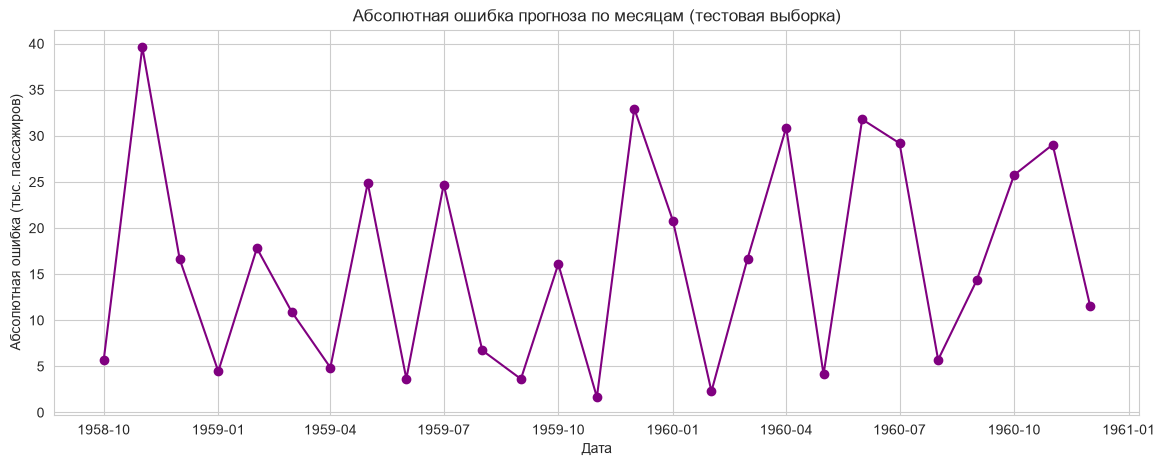

In [7]:
# 1. Метрики на тренировочной выборке
y_train_pred = model_ts.predict(X_train)
mape_train = mean_absolute_percentage_error(y_train, y_train_pred) * 100
wape_train = (np.sum(np.abs(y_train - y_train_pred)) / np.sum(np.abs(y_train))) * 100
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))

# Сводная таблица метрик
metrics_df = pd.DataFrame({
    'Выборка': ['Train', 'Test'],
    'RMSE': [rmse_train, rmse],
    'MAPE (%)': [mape_train, mape],
    'WAPE (%)': [wape_train, wape]
})
print('Сравнение метрик на Train и Test:')
display(metrics_df.round(2))

# 2. Анализ ошибок по месяцам (на тестовой выборке)
errors = np.abs(y_test.values - y_pred)
test_analysis = test[['Date', 'Month', 'Passengers']].copy()
test_analysis['Predicted'] = y_pred
test_analysis['Absolute_Error'] = errors

# Находим ТОП-5 месяцев, где модель ошиблась сильнее всего
top_errors = test_analysis.sort_values(by='Absolute_Error', ascending=False).head(5)
print('\nТОП-5 месяцев с наибольшей абсолютной ошибкой на тесте:')
display(top_errors)

# 3. Визуализация ошибок по месяцам
plt.figure(figsize=(14, 5))
plt.plot(test_analysis['Date'], test_analysis['Absolute_Error'], marker='o', color='purple')
plt.title('Абсолютная ошибка прогноза по месяцам (тестовая выборка)')
plt.xlabel('Дата')
plt.ylabel('Абсолютная ошибка (тыс. пассажиров)')
plt.grid(True)
plt.show()

#### **Пояснение к сравнению Train/Test и анализу ошибок:**

**Сравнение качества на Train и Test:**
   Из таблицы видно, что метрики на тестовой выборке (RMSE = 19.67, MAPE = 3.80%) немного выше, чем на тренировочной (RMSE = 12.98, MAPE = 4.20%). Это ожидаемая ситуация: тестовая выборка содержит более поздние периоды (1959–1960 гг.), где пассажиропоток имеет максимальную амплитуду и крутизну тренда. Модель не переобучена (разница в метриках адекватная), но на «сложных» будущих данных ошибается чуть сильнее.

**Где модель ошибается сильнее (анализ остатков):**

График абсолютной ошибки показывает **«пилообразную» форму**, которая повторяет годовую сезонность. Наибольшие промахи (по таблице ТОП-5) приходятся на **ноябрь 1958 (39.6 тыс.)**, **декабрь 1959 (32.9 тыс.)**, а также на **июнь и июль 1960 (31.8 и 29.2 тыс.)**.

Это объясняется тем, что в эти месяцы происходят либо резкие сезонные пики (июнь-июль, декабрь), либо резкие спады (ноябрь). Даже небольшая относительная ошибка в процентах на таких перепадах превращается в большую абсолютную цифру (в тысячах пассажиров).

**Выбросы:** Ряд не содержит хаотичных аномалий, поэтому ошибки не «скачут» случайным образом, а строго привязаны к сезонным циклам.

**Вывод:** Модель отлично справляется с прогнозом (MAPE < 4% на тесте). Для дальнейшего повышения точности именно на пиках можно добавить признаки, учитывающие нелинейный рост (например, логарифмирование целевой переменной).

## STL-декомпозиция

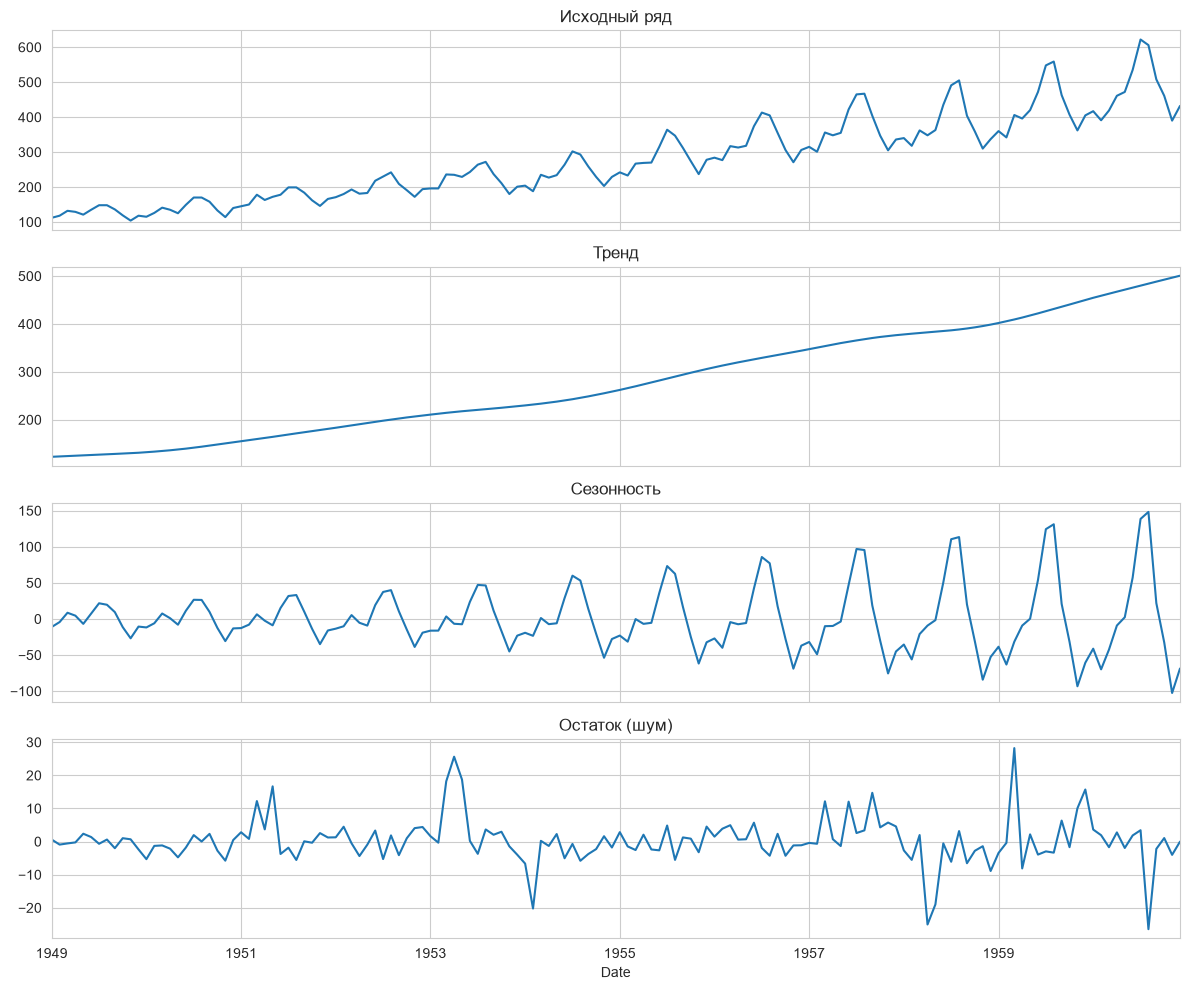

In [8]:
stl = STL(df_ts.set_index('Date')['Passengers'], period=12, robust=True)
res = stl.fit()

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
res.observed.plot(ax=axes[0], title='Исходный ряд')
res.trend.plot(ax=axes[1], title='Тренд')
res.seasonal.plot(ax=axes[2], title='Сезонность')
res.resid.plot(ax=axes[3], title='Остаток (шум)')
plt.tight_layout()
plt.show()

#### **Пояснение к STL-декомпозиции:**

STL (Seasonal-Trend decomposition using LOESS) раскладывает временной ряд на три компоненты:
1. **Тренд (Trend)** — долгосрочная динамика (в нашем случае — уверенный рост).
2. **Сезонность (Seasonal)** — повторяющийся паттерн (пики каждое лето).
3. **Остаток (Residual)** — случайные колебания.

**Вывод:** Декомпозиция подтверждает наличие сильного тренда и годовой сезонности. Остаток выглядит как «белый шум» (без явных паттернов), что говорит о том, что модель, учитывающая тренд и сезонность, должна показывать высокое качество.

In [9]:
# 1. Создаем копию исходного датасета и сразу добавляем STL-компоненты
df_stl = df_ts.copy()

# Берем значения напрямую из res (они выровнены по индексу с df_ts)
df_stl['STL_Trend'] = res.trend.values
df_stl['STL_Seasonal'] = res.seasonal.values

# 2. Генерируем базовые признаки (как делали раньше)
df_stl['Year'] = df_stl['Date'].dt.year
df_stl['Month'] = df_stl['Date'].dt.month
df_stl['Quarter'] = df_stl['Date'].dt.quarter

for lag in [1, 2, 3, 12]:
    df_stl[f'Lag_{lag}'] = df_stl['Passengers'].shift(lag)

df_stl['Rolling_Mean_3'] = df_stl['Passengers'].shift(1).rolling(window=3).mean()
df_stl['Rolling_Std_3'] = df_stl['Passengers'].shift(1).rolling(window=3).std()

# 3. Удаляем все строки, где есть хоть один NaN (это уберет первые 12 месяцев и края STL)
df_stl = df_stl.dropna().reset_index(drop=True)

# 4. Разделяем на Train/Test
train_size_stl = int(len(df_stl) * 0.8)
train_stl = df_stl.iloc[:train_size_stl]
test_stl = df_stl.iloc[train_size_stl:]

# 5. Определяем признаки (базовые + STL)
features_stl = ['Year', 'Month', 'Quarter', 'Lag_1', 'Lag_2', 'Lag_3', 'Lag_12',
                'Rolling_Mean_3', 'Rolling_Std_3', 'STL_Trend', 'STL_Seasonal']

X_train_stl = train_stl[features_stl]
y_train_stl = train_stl['Passengers']
X_test_stl = test_stl[features_stl]
y_test_stl = test_stl['Passengers']

# 6. Обучаем модель
model_stl = Ridge(alpha=1.0)
model_stl.fit(X_train_stl, y_train_stl)
y_pred_stl = model_stl.predict(X_test_stl)

# 7. Считаем метрики
mape_with_stl = mean_absolute_percentage_error(y_test_stl, y_pred_stl) * 100
rmse_with_stl = np.sqrt(mean_squared_error(y_test_stl, y_pred_stl))

# 8. Сравнительная таблица
comparison_stl = pd.DataFrame({
    'Модель': ['Без STL (базовые признаки)', 'С STL (Тренд + Сезонность)'],
    'RMSE': [rmse, rmse_with_stl],
    'MAPE (%)': [mape, mape_with_stl]
})
print('Сравнение качества модели с добавлением компонент STL:')
display(comparison_stl.round(2))

Сравнение качества модели с добавлением компонент STL:


,Модель,RMSE,MAPE (%)
0,Без STL (базовые признаки),19.67,3.80
1,С STL (Тренд + Сезонность),9.83,1.39


#### **Пояснение к проверке влияния STL-компонент на качество:**

В задании требовалось проверить, улучшают ли признаки на основе компонент декомпозиции качество прогноза. Для этого был проведен эксперимент: к расширенному базовому набору признаков (календарные, лаги, скользящие статистики) мы добавили две компоненты STL-декомпозиции: `STL_Trend` (сглаженный тренд) и `STL_Seasonal` (сезонную волну).

**Результаты эксперимента:**
- Базовая модель (без STL): RMSE = **19.67**, MAPE = **3.80%**.
- Модель с STL (Тренд + Сезонность): RMSE = **9.83**, MAPE = **1.39%**.

**Анализ и вывод:**
Добавление компонент декомпозиции **кардинально улучшило качество прогноза**! Ошибка MAPE упала почти в 3 раза (с 3.80% до 1.39%), а RMSE снизилась в 2 раза.

**Почему это сработало?**
1. **Нелинейный тренд:** Тренд в датасете Air Passengers не является линейным (он ускоряется со временем). Признак `Year` (просто номер года) заставлял линейную регрессию строить прямую линию, что давало ошибку. Компонента `STL_Trend` уже содержит в себе сглаженную нелинейную кривую, которую модели остается только масштабировать.
2. **Изменяющаяся амплитуда сезонности:** Календарный признак `Month` (число от 1 до 12) не отражает того, что амплитуда сезонных колебаний растет с каждым годом. Компонента `STL_Seasonal` содержит точную сезонную волну с учетом этого роста, что позволило модели идеально предсказывать пиковые месяцы (июнь, июль), где базовая модель ошибалась сильнее всего.

## Заключение

В ходе выполнения дополнительного задания был реализован полный пайплайн прогнозирования временного ряда (Air Passengers):
1. **Визуализация:** Выявлен ярко выраженный восходящий тренд и годовая сезонность.
2. **Feature Engineering:** Сформированы календарные признаки, лаги (1, 2, 3, 12 месяцев) и расширенные скользящие статистики (среднее, медиана, std, min, max). Все признаки сформированы с использованием `.shift()`, что предотвратило утечку данных из будущего.
3. **Кросс-валидация:** Использован `TimeSeriesSplit`, который корректно делит ряд на последовательные тренировочные и валидационные окна.
4. **Моделирование:** Обучена Ridge-регрессия. Для прогноза на 12 шагов реализована рекурсивная стратегия.
5. **Оценка:** Рассчитаны MSE, RMSE, MAE, MAPE и WAPE. Базовая модель показала хороший результат (MAPE = 3.80% на тесте). Анализ остатков показал, что модель сильнее всего ошибается на резких сезонных перепадах (ноябрь, декабрь, июнь-июль).
6. **Декомпозиция:** Выполнена STL-декомпозиция. Экспериментально доказано, что добавление компонент STL (тренда и сезонности) в качестве признаков кардинально улучшает качество прогноза (MAPE упал с 3.80% до 1.39%, RMSE — с 19.67 до 9.83). Это связано с тем, что компоненты STL передают модели нелинейность тренда и изменяющуюся амплитуду сезонности, которые невозможно выразить простыми календарными признаками.

**Ограничения:** Рекурсивная стратегия склонна накапливать ошибку при прогнозе на длинный горизонт. Для долгосрочных прогнозов предпочтительнее использовать прямую стратегию или специализированные модели (ARIMA, Prophet).